# Shape optimisation of the 25-bar space truss with displacement constraints

**Connectivity is fixed; node positions (and member areas, as in the literature) are continuous design variables.**

Benchmark: 25-bar transmission tower, size and shape version of Wu & Chow (1995), used by Gholizadeh (2013), Ho-Huu et al. (2016), Jawad et al. (2021) and others.
- 10 nodes (3D), 25 members, supports at nodes 7–10.
- Loads (kips): node 1 (1, −10, −10), node 2 (0, −10, −10), node 3 (0.5, 0, 0), node 6 (0.6, 0, 0).
- E = 10,000 ksi, ρ = 0.1 lb/in³.
- **Displacement |u| ≤ 0.35 in at every free node in x, y and z.** Stress |σ| ≤ 40 ksi.
- 8 area groups, 0.1 ≤ A ≤ 3.4 in².
- 5 shape variables with double symmetry: x4, y4, z4, x8, y8 (bounds below).
- Minimise weight W = ρ Σ A L.

**Method (physics-informed, gradient-based):** the design variables are bounded with a sigmoid. The linear FE equilibrium K(x, A) u = f is solved inside the loss, and PyTorch autograd gives the exact gradients of weight and constraints with respect to every node coordinate and area. Loss = W/W₀ + w_c Σ max(0, g − 1)², with the penalty w_c raised from 10 to 10⁴ so the final design sits on the constraint boundary. The final design is re-checked with an independent NumPy FE solve.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # Windows: NumPy (MKL) and PyTorch both ship libiomp5md.dll

import time
import numpy as np
import matplotlib.pyplot as plt
import torch

torch.set_default_dtype(torch.float64)

In [2]:
# 25-bar space truss - units: in, kips, ksi, lb. Node numbers as in the literature (1-based)
nodes0 = np.array([[-37.5, 0, 200], [37.5, 0, 200], [-37.5, 37.5, 100], [37.5, 37.5, 100], [37.5, -37.5, 100],
                   [-37.5, -37.5, 100], [-100, 100, 0], [100, 100, 0], [100, -100, 0], [-100, -100, 0]], dtype=float)
members = np.array([(1, 2), (1, 4), (2, 3), (1, 5), (2, 6), (2, 5), (2, 4), (1, 3), (1, 6), (3, 6), (4, 5), (3, 4), (5, 6),
                    (3, 10), (6, 7), (4, 9), (5, 8), (3, 8), (4, 7), (6, 9), (5, 10), (3, 7), (4, 8), (5, 9), (6, 10)]) - 1
groups = [[1], [2, 3, 4, 5], [6, 7, 8, 9], [10, 11], [12, 13], [14, 15, 16, 17], [18, 19, 20, 21], [22, 23, 24, 25]]
supports = [7, 8, 9, 10]
loads = {1: (1.0, -10.0, -10.0), 2: (0.0, -10.0, -10.0), 3: (0.5, 0.0, 0.0), 6: (0.6, 0.0, 0.0)}

E, rho = 1e4, 0.1
u_lim     = 0.35   # in   <-- displacement limit (every free node, x y z), change this
sigma_lim = 40.0   # ksi  stress limit (tension and compression)
A_min, A_max, A_init = 0.1, 3.4, 1.5
optimise_areas = True   # False: pure shape optimisation with all areas fixed at A_init

# Shape variables with double symmetry: (name, [(node, coordinate 0=x 1=y 2=z, sign)], lower, upper)
shape_vars = [("x4", [(4, 0, 1), (5, 0, 1), (3, 0, -1), (6, 0, -1)], 20, 60),
              ("y4", [(3, 1, 1), (4, 1, 1), (5, 1, -1), (6, 1, -1)], 40, 80),
              ("z4", [(3, 2, 1), (4, 2, 1), (5, 2, 1), (6, 2, 1)], 90, 130),
              ("x8", [(8, 0, 1), (9, 0, 1), (7, 0, -1), (10, 0, -1)], 40, 80),
              ("y8", [(7, 1, 1), (8, 1, 1), (9, 1, -1), (10, 1, -1)], 100, 140)]

# Reported optimum weights (discrete areas). Converted from kg where the source used SI (1 kg = 2.2046 lb)
literature = {
    "Wu & Chow (1995), GA":       136.20,
    "Gholizadeh (2013), PSO":     129.21,
    "Ho-Huu et al. (2016), DE":   118.76,
    "Jawad et al. (2021), ABC":   117.33,
    "MV-SMCTS (2023)":            116.76,
}

In [3]:
class TrussShapeProblem:
    """Shape + sizing optimisation of a truss with fixed connectivity (2D or 3D).
    Design variables: node coordinates (shape_vars) and member-group areas, both continuous and bounded."""

    def __init__(self, nodes0, members, groups, shape_vars, supports, loads, E, rho, A_min, A_max, A_init,
                 sigma_lim, K_buckling=None, u_lim=None, optimise_areas=True):
        self.nodes0 = torch.tensor(nodes0, dtype=torch.float64)
        self.members = members
        self.n_nodes, self.dim = nodes0.shape
        self.n_dof = self.n_nodes * self.dim
        self.E, self.rho = E, rho
        self.A_min, self.A_max = A_min, A_max
        self.sigma_lim, self.K_buckling, self.u_lim = sigma_lim, K_buckling, u_lim
        self.optimise_areas = optimise_areas

        self.grp = torch.zeros(len(members), dtype=torch.long)
        for g, mem in enumerate(groups):
            self.grp[np.array(mem) - 1] = g
        self.n_groups = len(groups)

        self.shape_vars = shape_vars
        self.lo = torch.tensor([s[2] for s in shape_vars], dtype=torch.float64)
        self.hi = torch.tensor([s[3] for s in shape_vars], dtype=torch.float64)
        v0 = torch.tensor([nodes0[s[1][0][0] - 1, s[1][0][1]] * s[1][0][2] for s in shape_vars])

        fixed = [self.dim * (k - 1) + d for k in supports for d in range(self.dim)]
        self.free = torch.tensor(np.setdiff1d(np.arange(self.n_dof), fixed))
        self.F = torch.zeros(self.n_dof)
        for k, p in loads.items():
            self.F[self.dim * (k - 1): self.dim * k] = torch.tensor(p, dtype=torch.float64)

        self.edofs = torch.tensor(np.hstack([self.dim * members[:, [0]] + np.arange(self.dim),
                                             self.dim * members[:, [1]] + np.arange(self.dim)]))

        # Bounded design variables through a sigmoid: value = lower + (upper - lower) * sigmoid(parameter)
        logit = lambda p: torch.log(p / (1 - p))
        a0 = torch.full((self.n_groups,), (A_init - A_min) / (A_max - A_min), dtype=torch.float64)
        s0 = ((v0 - self.lo) / (self.hi - self.lo)).clamp(0.02, 0.98)
        self.a_par = torch.nn.Parameter(logit(a0), requires_grad=optimise_areas)
        self.s_par = torch.nn.Parameter(logit(s0))

    def design(self):
        A = self.A_min + (self.A_max - self.A_min) * torch.sigmoid(self.a_par)
        v = self.lo + (self.hi - self.lo) * torch.sigmoid(self.s_par)
        X = self.nodes0.clone()
        for k, (name, links, lo, hi) in enumerate(self.shape_vars):
            for node, c, sign in links:
                X[node - 1, c] = sign * v[k]
        return A, v, X

    def analyse(self, A, X):
        # Linear FE, differentiable w.r.t. areas and node coordinates
        Am = A[self.grp]
        d = X[self.members[:, 1]] - X[self.members[:, 0]]
        L = d.norm(dim=1)
        c = d / L[:, None]
        t = torch.cat([-c, c], dim=1)
        ke = (self.E * Am / L)[:, None, None] * t[:, :, None] * t[:, None, :]
        nd2 = 2 * self.dim
        K = torch.zeros(self.n_dof, self.n_dof)
        K.index_put_((self.edofs[:, :, None].expand(-1, nd2, nd2), self.edofs[:, None, :].expand(-1, nd2, nd2)),
                     ke, accumulate=True)
        u = torch.zeros(self.n_dof)
        u = u.index_put((self.free,), torch.linalg.solve(K[self.free][:, self.free], self.F[self.free]))
        sigma = self.E * (t * u[self.edofs]).sum(1) / L
        return u, sigma, L, Am

    def constraint_ratios(self, u, sigma, L, Am):
        # every ratio must be <= 1
        s_c = torch.full_like(sigma, self.sigma_lim)
        if self.K_buckling is not None:
            s_c = torch.minimum(s_c, self.K_buckling * self.E * Am / L**2)       # Euler buckling
        g = {"tension": torch.relu(sigma) / self.sigma_lim, "compression": torch.relu(-sigma) / s_c}
        if self.u_lim is not None:
            g["displacement"] = u[self.free].abs() / self.u_lim
        return g

    def weight(self, L, Am):
        return self.rho * (Am * L).sum()

In [4]:
def optimise(prob, epochs=8000, lr=2e-2, w_start=1e1, w_end=1e4, print_every=1000, n_snapshots=6):
    params = [prob.s_par] + ([prob.a_par] if prob.optimise_areas else [])
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=1e-4)
    hist = {"W": [], "g_max": [], "snapshots": []}
    snap_at = set(np.linspace(0, epochs - 1, n_snapshots).astype(int))
    W0 = None
    t0 = time.time()

    for ep in range(epochs):
        w_c = w_start * (w_end / w_start) ** (ep / epochs)        # penalty weight raised geometrically
        A, v, X = prob.design()
        u, sigma, L, Am = prob.analyse(A, X)
        g = torch.cat(list(prob.constraint_ratios(u, sigma, L, Am).values()))
        W = prob.weight(L, Am)
        if W0 is None:
            W0 = W.item()
        loss = W / W0 + w_c * (torch.relu(g - 1) ** 2).sum()

        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()

        hist["W"].append(W.item())
        hist["g_max"].append(g.max().item())
        if ep in snap_at:
            hist["snapshots"].append((ep, X.detach().numpy().copy(), A.detach().numpy().copy(), W.item(), g.max().item()))
        if (ep + 1) % print_every == 0:
            print(f"Epoch {ep+1}: W = {W.item():.2f} lb, max constraint ratio = {g.max().item():.4f}")

    print(f"Optimisation time: {time.time() - t0:.1f} s")
    return hist

In [5]:
def fe_check(X, members, A_members, E, F, supports):
    # Independent NumPy FE solve of the final design (no autograd)
    n, dim = X.shape
    K = np.zeros((n * dim, n * dim))
    d = X[members[:, 1]] - X[members[:, 0]]
    L = np.linalg.norm(d, axis=1)
    c = d / L[:, None]
    for e, (i, j) in enumerate(members):
        t = np.r_[-c[e], c[e]]
        idx = np.r_[dim * i + np.arange(dim), dim * j + np.arange(dim)]
        K[np.ix_(idx, idx)] += E * A_members[e] / L[e] * np.outer(t, t)
    fixed = [dim * (k - 1) + q for k in supports for q in range(dim)]
    free = np.setdiff1d(np.arange(n * dim), fixed)
    u = np.zeros(n * dim)
    u[free] = np.linalg.solve(K[np.ix_(free, free)], F[free])
    du = u.reshape(n, dim)[members[:, 1]] - u.reshape(n, dim)[members[:, 0]]
    return u, E * (c * du).sum(1) / L, L

In [6]:
prob = TrussShapeProblem(nodes0, members, groups, shape_vars, supports, loads, E, rho, A_min, A_max, A_init,
                         sigma_lim, u_lim=u_lim, optimise_areas=optimise_areas)

# ~15 s on CPU
hist = optimise(prob, epochs=8000)

Epoch 1000: W = 119.92 lb, max constraint ratio = 1.0044
Epoch 2000: W = 117.96 lb, max constraint ratio = 1.0019
Epoch 3000: W = 117.41 lb, max constraint ratio = 1.0010
Epoch 4000: W = 117.21 lb, max constraint ratio = 1.0004
Epoch 5000: W = 117.13 lb, max constraint ratio = 1.0001
Epoch 6000: W = 117.08 lb, max constraint ratio = 1.0000
Epoch 7000: W = 117.05 lb, max constraint ratio = 1.0000
Epoch 8000: W = 117.04 lb, max constraint ratio = 1.0000
Optimisation time: 25.9 s


In [7]:
with torch.no_grad():
    A_opt, v_opt, X_opt = prob.design()
A_opt, v_opt, X_opt = A_opt.numpy(), v_opt.numpy(), X_opt.numpy()
A_mem = A_opt[prob.grp.numpy()]

# Independent check of the final design
F = prob.F.numpy()
u, sigma, L = fe_check(X_opt, members, A_mem, E, F, supports)
W = rho * (A_mem * L).sum()
u_free = u.reshape(-1, 3)[:6]
print(f"Optimised weight: {W:.2f} lb   (initial geometry, A = {A_init}: {hist['W'][0]:.2f} lb)")
print(f"Max |u| = {np.abs(u_free).max():.4f} in (limit {u_lim}),  max |sigma| = {np.abs(sigma).max():.3f} ksi (limit {sigma_lim})\n")

print(f"{'Variable':>8} | {'Initial':>8} | {'This work':>9}")
print("-" * 32)
init_v = [A_init] * len(A_opt) + [nodes0[s[1][0][0] - 1, s[1][0][1]] * s[1][0][2] for s in shape_vars]
names = [f"A{k+1}" for k in range(len(A_opt))] + [s[0] for s in shape_vars]
for i, name in enumerate(names):
    ours = A_opt[i] if i < len(A_opt) else v_opt[i - len(A_opt)]
    print(f"{name:>8} | {init_v[i]:>8.2f} | {ours:>9.3f}")
print(f"{'W (lb)':>8} | {hist['W'][0]:>8.2f} | {W:>9.2f}")

print("\nReported optimum weights (discrete areas):")
for k, w in literature.items():
    print(f"   {k:<28} {w:8.2f} lb")
print(f"   {'This work (continuous areas)':<28} {W:8.2f} lb")

print("\nNodal displacements (in):")
print(f"{'Node':>4} | {'ux':>8} | {'uy':>8} | {'uz':>8} | {'max|u|/limit':>12}")
for k in range(6):
    print(f"{k+1:>4} | {u_free[k, 0]:>8.4f} | {u_free[k, 1]:>8.4f} | {u_free[k, 2]:>8.4f} | {np.abs(u_free[k]).max() / u_lim:>12.3f}")

Optimised weight: 117.04 lb   (initial geometry, A = 1.5: 482.20 lb)
Max |u| = 0.3500 in (limit 0.35),  max |sigma| = 18.848 ksi (limit 40.0)

Variable |  Initial | This work
--------------------------------
      A1 |     1.50 |     0.101
      A2 |     1.50 |     0.102
      A3 |     1.50 |     0.937
      A4 |     1.50 |     0.100
      A5 |     1.50 |     0.101
      A6 |     1.50 |     0.101
      A7 |     1.50 |     0.110
      A8 |     1.50 |     0.915
      x4 |    37.50 |    37.464
      y4 |    37.50 |    56.019
      z4 |   100.00 |   128.762
      x8 |   100.00 |    49.995
      y8 |   100.00 |   139.990
  W (lb) |   482.20 |    117.04

Reported optimum weights (discrete areas):
   Wu & Chow (1995), GA           136.20 lb
   Gholizadeh (2013), PSO         129.21 lb
   Ho-Huu et al. (2016), DE       118.76 lb
   Jawad et al. (2021), ABC       117.33 lb
   MV-SMCTS (2023)                116.76 lb
   This work (continuous areas)   117.04 lb

Nodal displacements (in):
Node |   

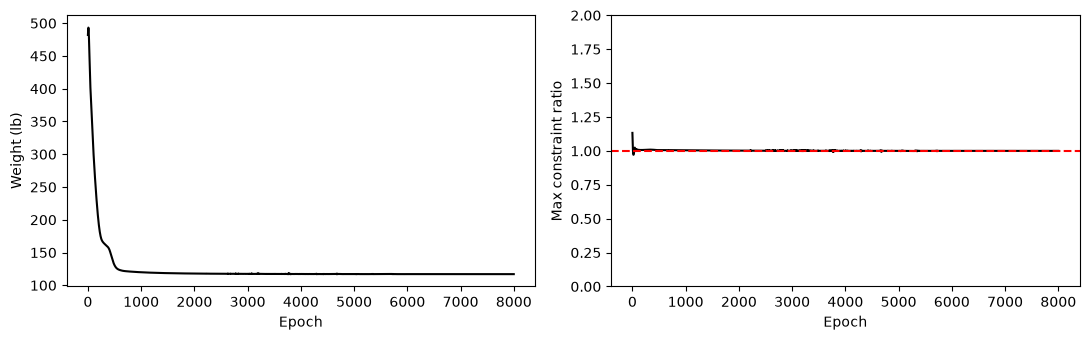

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(hist["W"], "k")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Weight (lb)")
ax2.plot(hist["g_max"], "k")
ax2.axhline(1.0, color="r", ls="--")
ax2.set_ylim(0, 2)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Max constraint ratio")
plt.tight_layout()
plt.show()

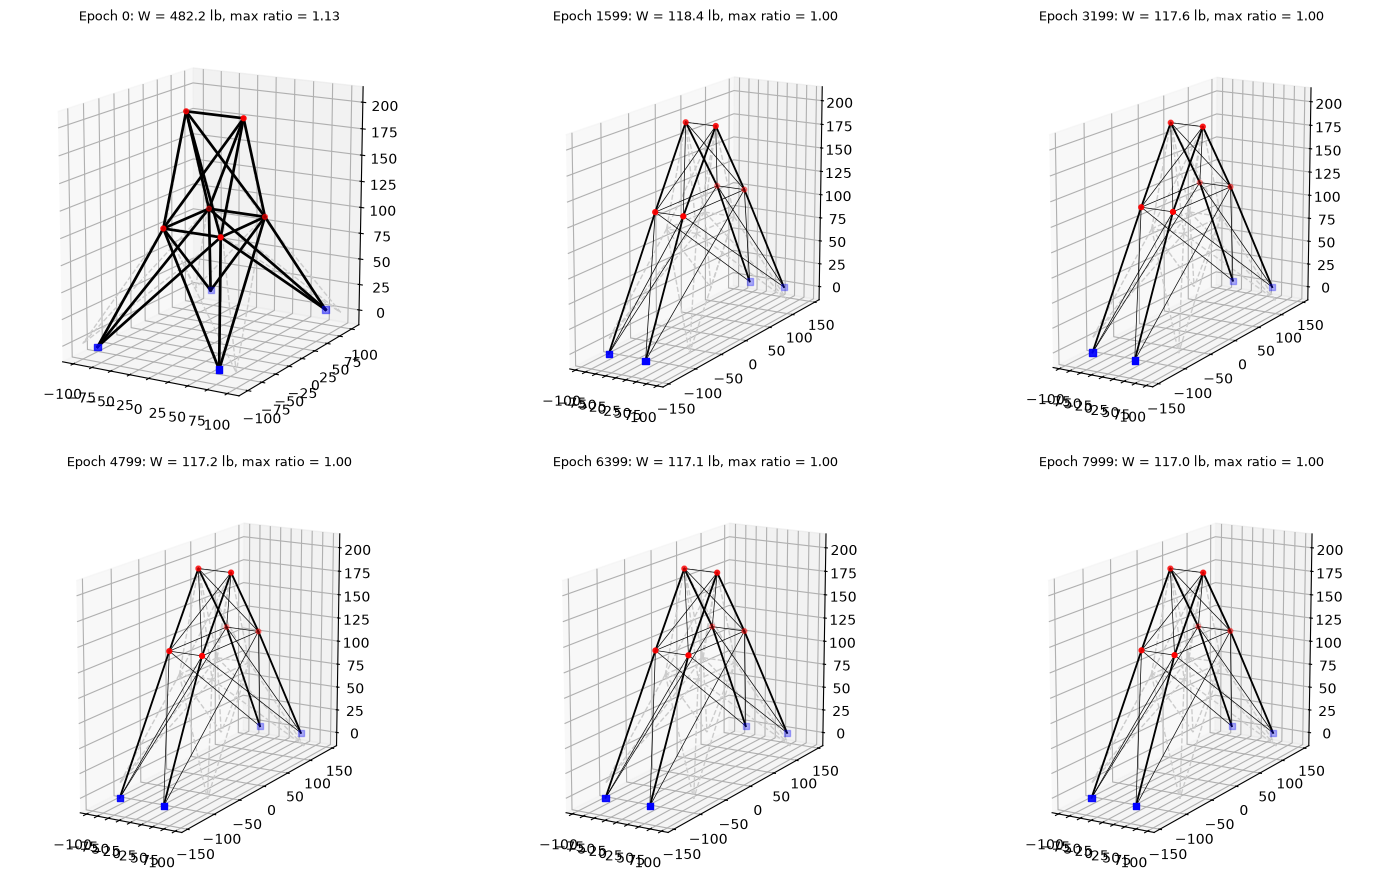

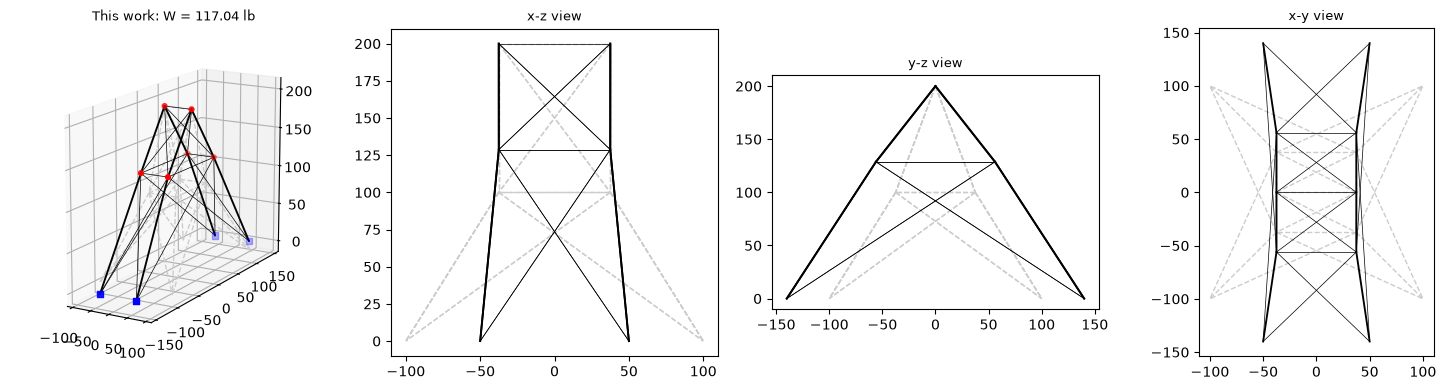

In [9]:
def plot_shape(ax, X, A, title, X_ref=None):
    if X_ref is not None:
        for i, j in members:
            ax.plot(X_ref[[i, j], 0], X_ref[[i, j], 1], X_ref[[i, j], 2], color="0.8", lw=1, ls="--")
    Am = A[prob.grp.numpy()]
    for e, (i, j) in enumerate(members):
        ax.plot(X[[i, j], 0], X[[i, j], 1], X[[i, j], 2], "k", lw=0.4 + 3.5 * Am[e] / A_max)
    ax.scatter(X[:6, 0], X[:6, 1], X[:6, 2], c="r", s=12)
    ax.scatter(X[6:, 0], X[6:, 1], X[6:, 2], c="b", marker="s", s=20)
    ax.set_box_aspect((np.ptp(X[:, 0]), np.ptp(X[:, 1]), np.ptp(X[:, 2])))
    ax.view_init(elev=15, azim=-60)
    ax.set_title(title, fontsize=9)

# Evolution of the geometry during optimisation (line width proportional to area; dashed = initial)
snaps = hist["snapshots"]
fig = plt.figure(figsize=(15, 9))
for k, (ep, X, A, Wk, gk) in enumerate(snaps):
    ax = fig.add_subplot(2, 3, k + 1, projection="3d")
    plot_shape(ax, X, A, f"Epoch {ep}: W = {Wk:.1f} lb, max ratio = {gk:.2f}", X_ref=nodes0)
plt.tight_layout()
plt.show()

# Final design: 3D view and the three projections
fig = plt.figure(figsize=(15, 4))
ax = fig.add_subplot(1, 4, 1, projection="3d")
plot_shape(ax, X_opt, A_opt, f"This work: W = {W:.2f} lb", X_ref=nodes0)
for k, (a, b, lab) in enumerate([(0, 2, "x-z"), (1, 2, "y-z"), (0, 1, "x-y")]):
    ax = fig.add_subplot(1, 4, k + 2)
    for i, j in members:
        ax.plot(nodes0[[i, j], a], nodes0[[i, j], b], color="0.8", lw=1, ls="--")
    for e, (i, j) in enumerate(members):
        ax.plot(X_opt[[i, j], a], X_opt[[i, j], b], "k", lw=0.4 + 3.5 * A_mem[e] / A_max)
    ax.set_aspect("equal")
    ax.set_title(f"{lab} view", fontsize=9)
plt.tight_layout()
plt.show()